In [2]:
# ============================================
# NIGERIAFLOODWATCH
# Task 3.4: Local Lokoja Floodplain Analysis
# ============================================

from pathlib import Path
import zipfile
import warnings

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

from shapely.geometry import Polygon, MultiPolygon
from shapely.validation import explain_validity

import os

os.environ["SHAPE_RESTORE_SHX"] = "YES"

warnings.filterwarnings("ignore", category=UserWarning)

# Project root
PROJECT_ROOT = Path("/workspaces/nigeria-flood-watch") 

# Source data directory
RAW_DIR = PROJECT_ROOT / "data" / "raw"

# Processed data directory
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

# Create processed directory if it does not exist
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Source archives
COPERNICUS_ZIP = (
        RAW_DIR /
            "EMSR314_02LOKOJA_01DELINEATION_MAP_v1_vector.zip"
)

LOKOJA_LGA_ZIP = (
        RAW_DIR /
            "lokoja_lga_utm32n.zip"
)

print("Project root:", PROJECT_ROOT)
print("Raw directory:", RAW_DIR)
print("Processed directory:", PROCESSED_DIR)

print("\nCopernicus archive exists:", COPERNICUS_ZIP.exists())
print("Lokoja LGA archive exists:", LOKOJA_LGA_ZIP.exists())


Project root: /workspaces/nigeria-flood-watch
Raw directory: /workspaces/nigeria-flood-watch/data/raw
Processed directory: /workspaces/nigeria-flood-watch/data/processed

Copernicus archive exists: True
Lokoja LGA archive exists: True


Inspecting the corpernicus archive

In [3]:
if not COPERNICUS_ZIP.exists():
    raise FileNotFoundError(
        f"Copernicus archive not found: {COPERNICUS_ZIP}"
    )

with zipfile.ZipFile(COPERNICUS_ZIP, "r") as archive:

    archive_contents = archive.namelist()

    print("Total files in archive:", len(archive_contents))
    print("\nARCHIVE CONTENTS:\n")

    for filename in archive_contents:
        print(filename)

Total files in archive: 52

ARCHIVE CONTENTS:

EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.dbf
EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.kmz
EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.prj
EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.shp
EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.shx
EMSR314_02LOKOJA_DEL_v1_built_up_a.dbf
EMSR314_02LOKOJA_DEL_v1_built_up_a.kmz
EMSR314_02LOKOJA_DEL_v1_built_up_a.prj
EMSR314_02LOKOJA_DEL_v1_built_up_a.shp
EMSR314_02LOKOJA_DEL_v1_built_up_a.shx
EMSR314_02LOKOJA_DEL_v1_facilities_p.dbf
EMSR314_02LOKOJA_DEL_v1_facilities_p.kmz
EMSR314_02LOKOJA_DEL_v1_facilities_p.prj
EMSR314_02LOKOJA_DEL_v1_facilities_p.shp
EMSR314_02LOKOJA_DEL_v1_facilities_p.shx
EMSR314_02LOKOJA_DEL_v1_hydrography_a.dbf
EMSR314_02LOKOJA_DEL_v1_hydrography_a.kmz
EMSR314_02LOKOJA_DEL_v1_hydrography_a.prj
EMSR314_02LOKOJA_DEL_v1_hydrography_a.shp
EMSR314_02LOKOJA_DEL_v1_hydrography_a.shx
EMSR314_02LOKOJA_DEL_v1_hydrography_l.dbf
EMSR314_02LOKOJA_DEL_v1_hydrography_l.kmz
EMSR314_02LOKOJA_DEL_v1_

In [4]:
# Identify relevant shapefile components

keywords = [
    "observed_event_a",
    "area_of_interest_a",
    "hydrography_a",
    "hydrography_l",
    "built_up_a",
    "transportation_l",
    "physiography_l"
]

print("\nRELEVANT FILES:\n")

for filename in archive_contents:
    if any(keyword.lower() in filename.lower() for keyword in keywords):
        print(filename)


RELEVANT FILES:

EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.dbf
EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.kmz
EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.prj
EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.shp
EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.shx
EMSR314_02LOKOJA_DEL_v1_built_up_a.dbf
EMSR314_02LOKOJA_DEL_v1_built_up_a.kmz
EMSR314_02LOKOJA_DEL_v1_built_up_a.prj
EMSR314_02LOKOJA_DEL_v1_built_up_a.shp
EMSR314_02LOKOJA_DEL_v1_built_up_a.shx
EMSR314_02LOKOJA_DEL_v1_hydrography_a.dbf
EMSR314_02LOKOJA_DEL_v1_hydrography_a.kmz
EMSR314_02LOKOJA_DEL_v1_hydrography_a.prj
EMSR314_02LOKOJA_DEL_v1_hydrography_a.shp
EMSR314_02LOKOJA_DEL_v1_hydrography_a.shx
EMSR314_02LOKOJA_DEL_v1_hydrography_l.dbf
EMSR314_02LOKOJA_DEL_v1_hydrography_l.kmz
EMSR314_02LOKOJA_DEL_v1_hydrography_l.prj
EMSR314_02LOKOJA_DEL_v1_hydrography_l.shp
EMSR314_02LOKOJA_DEL_v1_hydrography_l.shx
EMSR314_02LOKOJA_DEL_v1_observed_event_a.dbf
EMSR314_02LOKOJA_DEL_v1_observed_event_a.kmz
EMSR314_02LOKOJA_DEL_v1_observed_event_a.p

loading and inspecting the flood polygons

In [5]:
from pathlib import Path
import zipfile

EXTRACT_DIR = RAW_DIR / "EMSR314_02_extracted"

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(COPERNICUS_ZIP, "r") as archive:
    archive.extractall(EXTRACT_DIR)

print("Extraction completed.")
print("Extraction directory:", EXTRACT_DIR)

Extraction completed.
Extraction directory: /workspaces/nigeria-flood-watch/data/raw/EMSR314_02_extracted


In [6]:
flood_shapefiles = list(
    EXTRACT_DIR.rglob("EMSR314_02LOKOJA_DEL_v1_observed_event_a.shp")
)

if len(flood_shapefiles) != 1:
    raise FileNotFoundError(
        f"Expected one observed flood shapefile, found: {len(flood_shapefiles)}"
    )

flood_shapefile = flood_shapefiles[0]

print("Observed flood shapefile:", flood_shapefile)

print("\nSupporting files:")

for extension in [".shp", ".shx", ".dbf", ".prj"]:
    matches = list(
        flood_shapefile.parent.glob(f"{flood_shapefile.stem}{extension}")
    )
    print(extension, ":", bool(matches))

Observed flood shapefile: /workspaces/nigeria-flood-watch/data/raw/EMSR314_02_extracted/EMSR314_02LOKOJA_DEL_v1_observed_event_a.shp

Supporting files:
.shp : True
.shx : True
.dbf : True
.prj : True


In [7]:
# Allow GDAL to reconstruct missing SHX files in the writable directory
os.environ["SHAPE_RESTORE_SHX"] = "YES"

flood_gdf = gpd.read_file(flood_shapefile)

print("Flood layer loaded successfully.")

print("\nFeature count:", len(flood_gdf))
print("CRS:", flood_gdf.crs)

print("\nGeometry types:")
print(flood_gdf.geom_type.value_counts())

print("\nColumns:")
print(flood_gdf.columns.tolist())

print("\nBounding box:")
print(flood_gdf.total_bounds)

Flood layer loaded successfully.

Feature count: 1509
CRS: EPSG:4326

Geometry types:
Polygon         1496
MultiPolygon      13
Name: count, dtype: int64

Columns:
['event_type', 'obj_desc', 'det_method', 'notation', 'dmg_src_id', 'geometry']

Bounding box:
[6.70362823 7.7284658  7.00494625 7.97969175]


In [8]:
LGA_EXTRACT_DIR = RAW_DIR / "lokoja_lga_extracted"

LGA_EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(LOKOJA_LGA_ZIP, "r") as archive:
    archive.extractall(LGA_EXTRACT_DIR)

lga_shapefiles = list(LGA_EXTRACT_DIR.rglob("*.shp"))

if len(lga_shapefiles) != 1:
    raise ValueError(
        f"Expected one LGA shapefile, found: {len(lga_shapefiles)}"
    )

lokoja_lga = gpd.read_file(lga_shapefiles[0])

print("LOKOJA LGA LOADED")
print("Features:", len(lokoja_lga))
print("CRS:", lokoja_lga.crs)
print("Geometry:", lokoja_lga.geom_type.tolist())
print("Valid:", lokoja_lga.geometry.is_valid.all())

lokoja_lga_utm = lokoja_lga.to_crs("EPSG:32632")

print(
    "LGA area:",
    round(lokoja_lga_utm.geometry.area.sum() / 1_000_000, 4),
    "km²"
)

LOKOJA LGA LOADED
Features: 1
CRS: EPSG:32632
Geometry: ['Polygon']
Valid: True
LGA area: 3181.1678 km²


inspecting geometry validity and attributes

In [9]:


# Geometry validity
flood_gdf["geometry_valid"] = flood_gdf.geometry.is_valid

validity_summary = (
    flood_gdf["geometry_valid"]
    .value_counts(dropna=False)
)

print("GEOMETRY VALIDITY")
print(validity_summary)

print("\nInvalid geometries:")
print((~flood_gdf["geometry_valid"]).sum())

# Geometry type summary
print("\nGEOMETRY TYPES")
print(flood_gdf.geom_type.value_counts())

# Null and empty geometry checks
print("\nNULL GEOMETRIES:")
print(flood_gdf.geometry.isna().sum())

print("\nEMPTY GEOMETRIES:")
print(flood_gdf.geometry.is_empty.sum())

# Attribute completeness
print("\nATTRIBUTE NULL COUNTS:")
print(flood_gdf.drop(columns="geometry").isna().sum())

# Unique attribute values
for column in flood_gdf.columns:
    if column != "geometry" and column != "geometry_valid":
        print(f"\n{column.upper()} — UNIQUE VALUES")
        print(flood_gdf[column].value_counts(dropna=False).head(20))

# Explain invalid geometry reasons
invalid_flood = flood_gdf.loc[~flood_gdf["geometry_valid"]].copy()

print("\nINVALID GEOMETRY REASONS:")

for index, geometry in invalid_flood.geometry.head(10).items():
    print(index, ":", explain_validity(geometry))

GEOMETRY VALIDITY
geometry_valid
True     1405
False     104
Name: count, dtype: int64

Invalid geometries:
104

GEOMETRY TYPES
Polygon         1496
MultiPolygon      13
Name: count, dtype: int64

NULL GEOMETRIES:
0

EMPTY GEOMETRIES:
0

ATTRIBUTE NULL COUNTS:
event_type        0
obj_desc          0
det_method        0
notation          0
dmg_src_id        0
geometry_valid    0
dtype: int64

EVENT_TYPE — UNIQUE VALUES
event_type
5-Flood    1509
Name: count, dtype: int64

OBJ_DESC — UNIQUE VALUES
obj_desc
Riverine flood    1509
Name: count, dtype: int64

DET_METHOD — UNIQUE VALUES
det_method
Semi-automatic extraction    1509
Name: count, dtype: int64

NOTATION — UNIQUE VALUES
notation
Flooded area    1509
Name: count, dtype: int64

DMG_SRC_ID — UNIQUE VALUES
dmg_src_id
2    1509
Name: count, dtype: int64

INVALID GEOMETRY REASONS:
18 : Ring Self-intersection[6.76511791400003 7.74529034700004]
53 : Ring Self-intersection[6.76880100600005 7.76505328300004]
68 : Ring Self-intersection[6.77

loading the lokoja lga boundary

In [10]:
import zipfile
from pathlib import Path
import os

os.environ["SHAPE_RESTORE_SHX"] = "YES"

LGA_EXTRACT_DIR = RAW_DIR / "lokoja_lga_extracted"
LGA_EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(LOKOJA_LGA_ZIP, "r") as archive:
    archive.extractall(LGA_EXTRACT_DIR)

print("Extraction complete.")

for path in LGA_EXTRACT_DIR.rglob("*"):
    if path.is_file():
        print(path.name, path.stat().st_size, "bytes")

Extraction complete.
lokoja_lga_utm32n.sbx 116 bytes
lokoja_lga_utm32n.prj 402 bytes
lokoja_lga_utm32n.dbf 1307 bytes
lokoja_lga_utm32n.sbn 132 bytes
lokoja_lga_utm32n.shp 3548 bytes
lokoja_lga_utm32n.shx 108 bytes
EMSR314_02LOKOJA_01DELINEATION_MAP_v1_vector.zip 6556177 bytes


In [11]:
lga_shapefiles = list(LGA_EXTRACT_DIR.rglob("*.shp"))

if len(lga_shapefiles) != 1:
    raise ValueError(
        f"Expected one shapefile, found {len(lga_shapefiles)}"
    )

lga_shapefile = lga_shapefiles[0]

print("Reading:", lga_shapefile)

lokoja_lga = gpd.read_file(lga_shapefile)

print("\nLOKOJA LGA LOADED")
print("Features:", len(lokoja_lga))
print("CRS:", lokoja_lga.crs)
print("Geometry types:", lokoja_lga.geom_type.value_counts())
print("Valid:", lokoja_lga.geometry.is_valid.all())
print("Null geometries:", lokoja_lga.geometry.isna().sum())
print("Empty geometries:", lokoja_lga.geometry.is_empty.sum())

lokoja_lga_utm = lokoja_lga.to_crs("EPSG:32632")

print(
    "Area:",
    round(lokoja_lga_utm.geometry.area.sum() / 1_000_000, 4),
    "km²"
)

Reading: /workspaces/nigeria-flood-watch/data/raw/lokoja_lga_extracted/lokoja_lga_utm32n.shp

LOKOJA LGA LOADED
Features: 1
CRS: EPSG:32632
Geometry types: Polygon    1
Name: count, dtype: int64
Valid: True
Null geometries: 0
Empty geometries: 0
Area: 3181.1678 km²


visualising inspection of both datasets

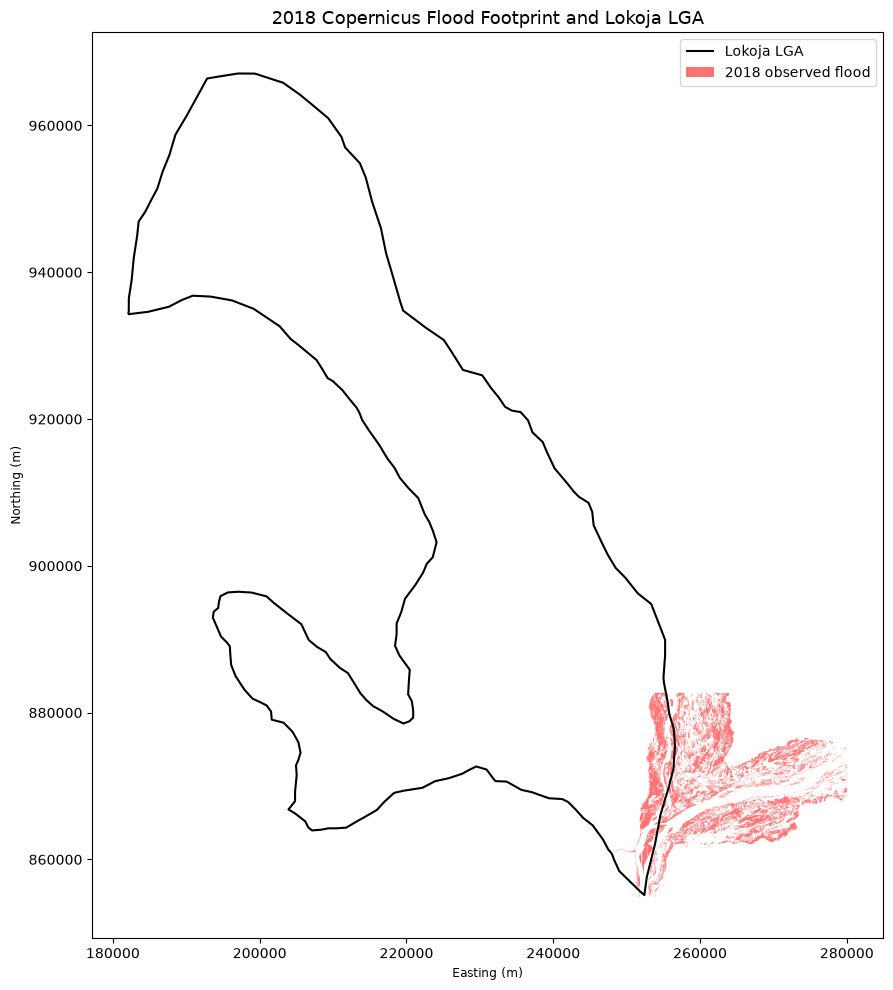

In [12]:
flood_utm = flood_gdf.to_crs("EPSG:32632")

fig, ax = plt.subplots(figsize=(10, 10))

lokoja_lga_utm.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.5,
    label="Lokoja LGA"
)

flood_utm.plot(
    ax=ax,
    color="red",
    alpha=0.55,
    edgecolor="none",
    label="2018 observed flood"
)

ax.set_title(
    "2018 Copernicus Flood Footprint and Lokoja LGA",
    fontsize=13
)

ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")

ax.legend()
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

clean, clip and export the 2018 flood evidence

GEOMETRY REPAIR
Invalid flood geometries before: 104
Invalid flood geometries after: 0
Flood features retained: 1509

SPATIAL RESULTS
------------------------------
Flood features before clipping: 1509
Flood features after clipping: 54
Lokoja LGA area: 3181.1678 km²
Sum of clipped feature areas: 36.009 km²
Unique mapped flood area: 36.009 km²
Share of LGA area: 1.1319 %

EXPORTED FILES
/workspaces/nigeria-flood-watch/notebooks/data/processed/lokoja_lga_boundary.geojson
/workspaces/nigeria-flood-watch/notebooks/data/processed/lokoja_2018_flood_extent.geojson


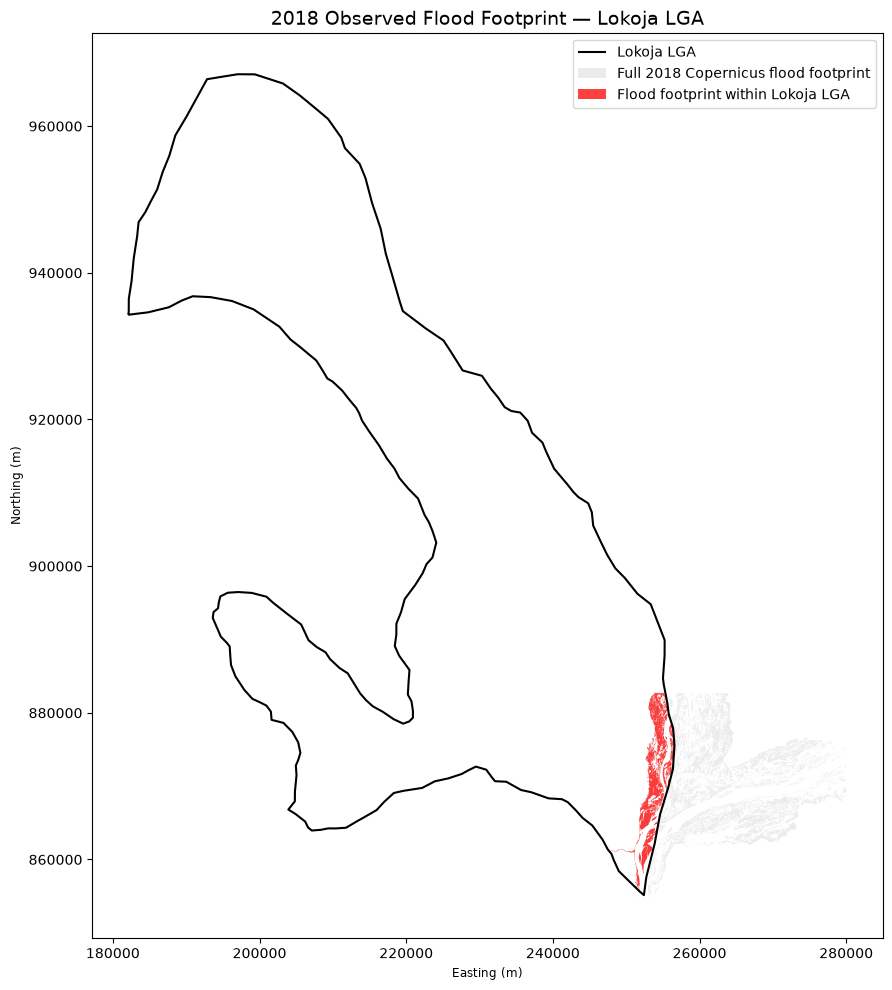


Map saved: /workspaces/nigeria-flood-watch/notebooks/data/figures/lokoja_2018_flood_extent_clipped_qa.png

FINAL QUALITY CHECK
------------------------------
LGA geometries valid: True
Clipped flood geometries valid: True
Flood CRS: EPSG:4326
LGA CRS: EPSG:4326
Flood null geometries: 0
Flood empty geometries: 0

TASK 3.4.1 PROCESSING COMPLETE


In [13]:
from pathlib import Path
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import shapely
from shapely.ops import unary_union

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "data" / "figures"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

ANALYSIS_CRS = "EPSG:32632"
OUTPUT_CRS = "EPSG:4326"

# Confirm source objects exist
assert "flood_gdf" in globals(), "flood_gdf is not loaded."
assert "lokoja_lga" in globals(), "lokoja_lga is not loaded."

assert flood_gdf.crs is not None, "Flood layer has no CRS."
assert lokoja_lga.crs is not None, "LGA boundary has no CRS."

# ------------------------------------------------------------
# 2. PRESERVE AND PREPARE SOURCE DATA
# ------------------------------------------------------------

flood_work = flood_gdf.copy()
lga_work = lokoja_lga.copy()

# Remove null and empty geometries from the working copies
flood_work = flood_work.loc[
    flood_work.geometry.notna() &
    ~flood_work.geometry.is_empty
].copy()

lga_work = lga_work.loc[
    lga_work.geometry.notna() &
    ~lga_work.geometry.is_empty
].copy()

# ------------------------------------------------------------
# 3. REPAIR INVALID GEOMETRIES
# ------------------------------------------------------------

invalid_before = (~flood_work.geometry.is_valid).sum()

flood_work["geometry"] = flood_work.geometry.apply(
    lambda geom: shapely.make_valid(geom)
)

# Keep polygonal components only if repair produced collections
def extract_polygonal(geom):
    if geom is None or geom.is_empty:
        return None

    if geom.geom_type == "Polygon":
        return geom

    if geom.geom_type == "MultiPolygon":
        return geom

    if geom.geom_type == "GeometryCollection":
        polygons = [
            part for part in geom.geoms
            if part.geom_type in ["Polygon", "MultiPolygon"]
            and not part.is_empty
        ]

        if polygons:
            return shapely.union_all(polygons)

    return None


flood_work["geometry"] = flood_work.geometry.apply(
    extract_polygonal
)

flood_work = flood_work.loc[
    flood_work.geometry.notna() &
    ~flood_work.geometry.is_empty
].copy()

invalid_after = (~flood_work.geometry.is_valid).sum()

# Repair LGA if necessary, without altering source
lga_work["geometry"] = lga_work.geometry.apply(
    lambda geom: shapely.make_valid(geom)
)

if (~lga_work.geometry.is_valid).any():
    raise ValueError("LGA boundary still contains invalid geometries.")

print("GEOMETRY REPAIR")
print("Invalid flood geometries before:", invalid_before)
print("Invalid flood geometries after:", invalid_after)
print("Flood features retained:", len(flood_work))

if invalid_after > 0:
    raise ValueError("Some flood geometries remain invalid.")

# ------------------------------------------------------------
# 4. PROJECT TO METRIC CRS
# ------------------------------------------------------------

flood_utm = flood_work.to_crs(ANALYSIS_CRS)
lga_utm = lga_work.to_crs(ANALYSIS_CRS)

# Dissolve LGA features into one clipping geometry
lga_union = lga_utm.geometry.union_all()

# ------------------------------------------------------------
# 5. CLIP FLOOD POLYGONS TO LOKOJA LGA
# ------------------------------------------------------------

flood_clipped = gpd.clip(
    flood_utm,
    lga_union,
    keep_geom_type=True
)

flood_clipped = flood_clipped.loc[
    flood_clipped.geometry.notna() &
    ~flood_clipped.geometry.is_empty
].copy()

# Ensure polygon geometries only
flood_clipped = flood_clipped.loc[
    flood_clipped.geom_type.isin(["Polygon", "MultiPolygon"])
].copy()

if len(flood_clipped) == 0:
    raise ValueError("No flood polygons intersect the Lokoja LGA boundary.")

flood_clipped["area_km2"] = (
    flood_clipped.geometry.area / 1_000_000
)

# ------------------------------------------------------------
# 6. CALCULATE AREA STATISTICS
# ------------------------------------------------------------

# Sum of individual feature areas
feature_area_km2 = flood_clipped["area_km2"].sum()

# Union area avoids double-counting overlapping polygons
flood_union = flood_clipped.geometry.union_all()
unique_flood_area_km2 = flood_union.area / 1_000_000

lga_area_km2 = lga_utm.geometry.area.sum() / 1_000_000

coverage_percentage = (
    unique_flood_area_km2 / lga_area_km2
) * 100

print("\nSPATIAL RESULTS")
print("------------------------------")
print("Flood features before clipping:", len(flood_work))
print("Flood features after clipping:", len(flood_clipped))
print("Lokoja LGA area:", round(lga_area_km2, 4), "km²")
print("Sum of clipped feature areas:", round(feature_area_km2, 4), "km²")
print("Unique mapped flood area:", round(unique_flood_area_km2, 4), "km²")
print("Share of LGA area:", round(coverage_percentage, 4), "%")

# ------------------------------------------------------------
# 7. EXPORT OUTPUTS
# ------------------------------------------------------------

# Convert to geographic CRS for GeoJSON export
lga_export = lga_utm.to_crs(OUTPUT_CRS)
flood_export = flood_clipped.to_crs(OUTPUT_CRS)

lga_output = PROCESSED_DIR / "lokoja_lga_boundary.geojson"
flood_output = PROCESSED_DIR / "lokoja_2018_flood_extent.geojson"

lga_export.to_file(lga_output, driver="GeoJSON")
flood_export.to_file(flood_output, driver="GeoJSON")

print("\nEXPORTED FILES")
print(lga_output)
print(flood_output)

# ------------------------------------------------------------
# 8. GENERATE COMPARISON MAP
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 10))

lga_utm.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.5,
    label="Lokoja LGA"
)

flood_utm.plot(
    ax=ax,
    color="lightgrey",
    alpha=0.45,
    edgecolor="none",
    label="Full 2018 Copernicus flood footprint"
)

flood_clipped.plot(
    ax=ax,
    color="red",
    alpha=0.75,
    edgecolor="none",
    label="Flood footprint within Lokoja LGA"
)

ax.set_title(
    "2018 Observed Flood Footprint — Lokoja LGA",
    fontsize=14
)

ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.legend()
ax.set_aspect("equal")

plt.tight_layout()

map_output = FIGURES_DIR / "lokoja_2018_flood_extent_clipped_qa.png"

plt.savefig(map_output, dpi=300, bbox_inches="tight")
plt.show()

print("\nMap saved:", map_output)

# ------------------------------------------------------------
# 9. FINAL QUALITY CHECKS
# ------------------------------------------------------------

print("\nFINAL QUALITY CHECK")
print("------------------------------")
print("LGA geometries valid:", lga_export.geometry.is_valid.all())
print("Clipped flood geometries valid:", flood_export.geometry.is_valid.all())
print("Flood CRS:", flood_export.crs)
print("LGA CRS:", lga_export.crs)
print("Flood null geometries:", flood_export.geometry.isna().sum())
print("Flood empty geometries:", flood_export.geometry.is_empty.sum())

print("\nTASK 3.4.1 PROCESSING COMPLETE")


In [14]:
from pathlib import Path
import shutil

# Find the actual repository root
current = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        p for p in [current, *current.parents]
        if (p / ".git").exists() and (p / "data").is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not identify repository root.")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "data" / "figures"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Copy the existing outputs to their correct locations
outputs = {
    Path("data/processed/lokoja_lga_boundary.geojson"):
        PROCESSED_DIR / "lokoja_lga_boundary.geojson",

    Path("data/processed/lokoja_2018_flood_extent.geojson"):
        PROCESSED_DIR / "lokoja_2018_flood_extent.geojson",

    Path("data/figures/lokoja_2018_flood_extent_clipped_qa.png"):
        FIGURES_DIR / "lokoja_2018_flood_extent_clipped_qa.png",
}

for source, destination in outputs.items():
    source = current / source

    if not source.exists():
        raise FileNotFoundError(f"Missing source: {source}")

    shutil.copy2(source, destination)
    print("Copied:", destination)

print("\nRepository root:", PROJECT_ROOT)

Copied: /workspaces/nigeria-flood-watch/data/processed/lokoja_lga_boundary.geojson
Copied: /workspaces/nigeria-flood-watch/data/processed/lokoja_2018_flood_extent.geojson
Copied: /workspaces/nigeria-flood-watch/data/figures/lokoja_2018_flood_extent_clipped_qa.png

Repository root: /workspaces/nigeria-flood-watch


In [15]:
from pathlib import Path

root = PROJECT_ROOT

for folder in [
    root / "data" / "processed",
    root / "data" / "raw",
    root / "data" / "figures",
]:
    print(f"\n{folder.relative_to(root)}/")

    for item in sorted(folder.iterdir()):
        if item.is_file():
            print(f"  {item.name} ({item.stat().st_size:,} bytes)")
        elif item.is_dir():
            print(f"  {item.name}/")


data/processed/
  hydrobasins_combined_upstream_attributes_lokoja.csv (34,790 bytes)
  hydrobasins_combined_upstream_network_lokoja.geojson (6,770,548 bytes)
  hydrobasins_upstream_attributes_lokoja.csv (18,439 bytes)
  hydrobasins_upstream_network_lokoja.geojson (5,864,402 bytes)
  lokoja_2018_flood_extent.geojson (3,219,713 bytes)
  lokoja_lga_boundary.geojson (9,412 bytes)

data/raw/
  EMSR314_02LOKOJA_01DELINEATION_MAP_v1_vector.zip (13,116,876 bytes)
  EMSR314_02_extracted/
  lokoja_lga_extracted/
  lokoja_lga_utm32n.zip (6,560,581 bytes)

data/figures/
  lokoja_2018_flood_extent_clipped_qa.png (481,537 bytes)
  lokoja_local_floodplain_evidence_qa.png (778,306 bytes)
  lokoja_river_basin_overlay_qa.png (119,161 bytes)


inspecting the remaining copernicus spatial layers

In [16]:
from pathlib import Path
import geopandas as gpd
import pandas as pd

EXTRACT_DIR = (
    PROJECT_ROOT /
    "data" /
    "raw" /
    "EMSR314_02_extracted"
)

# Identify relevant Copernicus shapefiles
keywords = [
    "hydrography",
    "built_up",
    "transportation",
    "physiography",
    "area_of_interest",
    "observed_event"
]

shapefiles = list(EXTRACT_DIR.rglob("*.shp"))

print("COPERNICUS SUPPORTING LAYERS")
print("=" * 65)

layer_results = []

for shp in sorted(shapefiles):

    matching_keyword = next(
        (
            keyword for keyword in keywords
            if keyword.lower() in shp.stem.lower()
        ),
        None
    )

    if matching_keyword is None:
        continue

    gdf = gpd.read_file(shp)

    result = {
        "layer": shp.stem,
        "category": matching_keyword,
        "features": len(gdf),
        "crs": str(gdf.crs),
        "geometry_types": ", ".join(
            gdf.geom_type.value_counts().index.astype(str)
        ),
        "fields": ", ".join(
            str(c) for c in gdf.columns if c != "geometry"
        )
    }

    layer_results.append(result)

    print(f"\nLayer: {shp.stem}")
    print("Features:", len(gdf))
    print("CRS:", gdf.crs)
    print("Geometry types:")
    print(gdf.geom_type.value_counts())
    print("Attributes:")
    print(gdf.drop(columns="geometry").head(3))

layer_inventory = pd.DataFrame(layer_results)

print("\n\nCONSOLIDATED LAYER INVENTORY")
display(layer_inventory)


COPERNICUS SUPPORTING LAYERS

Layer: EMSR314_02LOKOJA_DEL_v1_area_of_interest_a
Features: 1
CRS: EPSG:4326
Geometry types:
Polygon    1
Name: count, dtype: int64
Attributes:
   emsr_id        glide_no area_id locality     map_type
0  EMSR314  Not Applicable      02   Lokoja  Delineation

Layer: EMSR314_02LOKOJA_DEL_v1_built_up_a
Features: 31
CRS: EPSG:4326
Geometry types:
Polygon    31
Name: count, dtype: int64
Attributes:
                   obj_type     name                info  \
0  11-Residential Buildings  Unknown  997-Not Applicable   
1  11-Residential Buildings  Unknown  997-Not Applicable   
2  11-Residential Buildings  Unknown  997-Not Applicable   

             det_method       notation  or_src_id  dmg_src_id        cd_value  \
0  Photo-interpretation  Built up area          1         997  Not Applicable   
1  Photo-interpretation  Built up area          1         997  Not Applicable   
2  Photo-interpretation  Built up area          1         997  Not Applicable   

       

,layer,category,features,crs,geometry_types,fields
0,EMSR314_02LOKOJA_DEL_v1_area_of_interest_a,area_of_interest,1,EPSG:4326,Polygon,"emsr_id, glide_no, area_id, locality, map_type"
1,EMSR314_02LOKOJA_DEL_v1_built_up_a,built_up,31,EPSG:4326,Polygon,"obj_type, name, info, det_method, notation, or..."
2,EMSR314_02LOKOJA_DEL_v1_hydrography_a,hydrography,108,EPSG:4326,"Polygon, MultiPolygon","obj_type, name, notation, or_src_id, cd_value"
3,EMSR314_02LOKOJA_DEL_v1_hydrography_l,hydrography,22,EPSG:4326,LineString,"obj_type, name, notation, or_src_id, cd_value"
4,EMSR314_02LOKOJA_DEL_v1_observed_event_a,observed_event,1509,EPSG:4326,"Polygon, MultiPolygon","event_type, obj_desc, det_method, notation, dm..."
5,EMSR314_02LOKOJA_DEL_v1_physiography_l,physiography,172,EPSG:4326,"LineString, MultiLineString","obj_type, name, elev, notation, or_src_id"
6,EMSR314_02LOKOJA_DEL_v1_transportation_l,transportation,47,EPSG:4326,LineString,"obj_type, name, info, det_method, notation, or..."
7,EMSR314_02LOKOJA_DEL_v1_transportation_p,transportation,7,EPSG:4326,Point,"obj_type, name, info, det_method, notation, or..."


inspecting the combined HydroBASINS network

In [17]:
NETWORK_FILE = (
    PROJECT_ROOT /
    "data" /
    "processed" /
    "hydrobasins_combined_upstream_network_lokoja.geojson"
)

ATTRIBUTES_FILE = (
    PROJECT_ROOT /
    "data" /
    "processed" /
    "hydrobasins_combined_upstream_attributes_lokoja.csv"
)

basins = gpd.read_file(NETWORK_FILE)
basin_attributes = pd.read_csv(ATTRIBUTES_FILE)

print("COMBINED UPSTREAM NETWORK")
print("Features:", len(basins))
print("CRS:", basins.crs)
print("Geometry types:")
print(basins.geom_type.value_counts())

print("\nNETWORK FIELDS:")
print(basins.columns.tolist())

print("\nATTRIBUTE TABLE:")
print(basin_attributes.shape)
print(basin_attributes.columns.tolist())

print("\nFIRST FIVE ATTRIBUTE RECORDS:")
display(basin_attributes.head())


COMBINED UPSTREAM NETWORK
Features: 297
CRS: EPSG:4326
Geometry types:
Polygon         295
MultiPolygon      2
Name: count, dtype: int64

NETWORK FIELDS:
['id', 'COAST', 'DIST_MAIN', 'DIST_SINK', 'ENDO', 'HYBAS_ID', 'MAIN_BAS', 'NEXT_DOWN', 'NEXT_SINK', 'ORDER', 'PFAF_ID', 'SORT', 'SUB_AREA', 'UP_AREA', 'branch_name', 'branch_seed', 'network_role', 'upstream_level', 'geometry']

ATTRIBUTE TABLE:
(297, 10)
['HYBAS_ID', 'NEXT_DOWN', 'MAIN_BAS', 'UP_AREA', 'SUB_AREA', 'PFAF_ID', 'upstream_level', 'branch_seed', 'branch_name', 'network_role']

FIRST FIVE ATTRIBUTE RECORDS:


,HYBAS_ID,NEXT_DOWN,MAIN_BAS,UP_AREA,SUB_AREA,PFAF_ID,upstream_level,branch_seed,branch_name,network_role
0,1060892990,1060909890,1060022420,1712299.0,20826.6,142330,1,1060909890,Target_A_1060909890,Upstream contributing basin
1,1060893000,1060909890,1060022420,15286.4,15286.4,142320,1,1060909890,Target_A_1060909890,Upstream contributing basin
2,1060870170,1060892990,1060022420,1625808.6,25992.3,142350,2,1060909890,Target_A_1060909890,Upstream contributing basin
3,1060870030,1060892990,1060022420,65667.3,5490.3,142341,2,1060909890,Target_A_1060909890,Upstream contributing basin
4,1060834440,1060870030,1060022420,17427.6,17426.7,142342,3,1060909890,Target_A_1060909890,Upstream contributing basin


In [18]:

# ============================================================
# HYDROBASINS NETWORK STRUCTURE DIAGNOSTICS
# ============================================================

print("BRANCH DISTRIBUTION")
display(
    basins.groupby(["branch_seed", "branch_name"])
    .size()
    .reset_index(name="basin_count")
)

print("\nNETWORK ROLE DISTRIBUTION")
display(
    basins["network_role"]
    .value_counts(dropna=False)
    .rename_axis("network_role")
    .reset_index(name="count")
)

print("\nUPSTREAM LEVEL DISTRIBUTION")
display(
    basins["upstream_level"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("upstream_level")
    .reset_index(name="count")
)

print("\nDUPLICATE BASIN IDs:", basins["HYBAS_ID"].duplicated().sum())

print(
    "Invalid basin geometries:",
    (~basins.geometry.is_valid).sum()
)


BRANCH DISTRIBUTION


,branch_seed,branch_name,basin_count
0,1060909890,Target_A_1060909890,256
1,1060909900,Target_B_1060909900,41



NETWORK ROLE DISTRIBUTION


,network_role,count
0,Upstream contributing basin,295
1,Target basin,2



UPSTREAM LEVEL DISTRIBUTION


,upstream_level,count
0,0,2
1,1,4
2,2,4
3,3,6
4,4,6
5,5,6
6,6,6
7,7,4
8,8,4
9,9,4



DUPLICATE BASIN IDs: 0
Invalid basin geometries: 0


In [19]:

display(
    layer_inventory[
        ["layer", "features", "crs", "geometry_types", "fields"]
    ].to_string(index=False)
)


'                                     layer  features       crs              geometry_types                                                                            fields\nEMSR314_02LOKOJA_DEL_v1_area_of_interest_a         1 EPSG:4326                     Polygon                                    emsr_id, glide_no, area_id, locality, map_type\n        EMSR314_02LOKOJA_DEL_v1_built_up_a        31 EPSG:4326                     Polygon obj_type, name, info, det_method, notation, or_src_id, dmg_src_id, cd_value, real\n     EMSR314_02LOKOJA_DEL_v1_hydrography_a       108 EPSG:4326       Polygon, MultiPolygon                                     obj_type, name, notation, or_src_id, cd_value\n     EMSR314_02LOKOJA_DEL_v1_hydrography_l        22 EPSG:4326                  LineString                                     obj_type, name, notation, or_src_id, cd_value\n  EMSR314_02LOKOJA_DEL_v1_observed_event_a      1509 EPSG:4326       Polygon, MultiPolygon                            event_type,

identifying the local river corridors and supporting features

HYDROGRAPHY POLYGONS
name
Unknown    104
Benue        3
Niger        1
Name: count, dtype: int64

HYDROGRAPHY LINES
name
Unknown    22
Name: count, dtype: int64

HYDROGRAPHY LINE OBJECT TYPES
obj_type
BH140-River    22
Name: count, dtype: int64

HYDROGRAPHY POLYGON OBJECT TYPES
obj_type
BH080-Lake          58
BH141-River Bank    46
BH140-River          4
Name: count, dtype: int64

BUILT-UP AREA NAMES
name
Unknown        16
Banda           2
Lokoja          2
Atakpa          1
Gbaroada        1
Emi Atsumbe     1
Odugbo          1
Mozum           1
Kpai            1
Kpatakpali      1
Gbonoko         1
Nyankpo         1
Kuroko          1
Oko             1
Name: count, dtype: int64

BUILT-UP OBJECT TYPES
obj_type
11-Residential Buildings    31
Name: count, dtype: int64

ROAD OBJECT TYPES
obj_type
211-Highways, Streets and Roads    47
Name: count, dtype: int64

TRANSPORT POINT TYPES
obj_type
214-Bridges, Elevated Highways, Tunnels and Subways    7
Name: count, dtype: int64

PHYSIOGRAPHY ELE

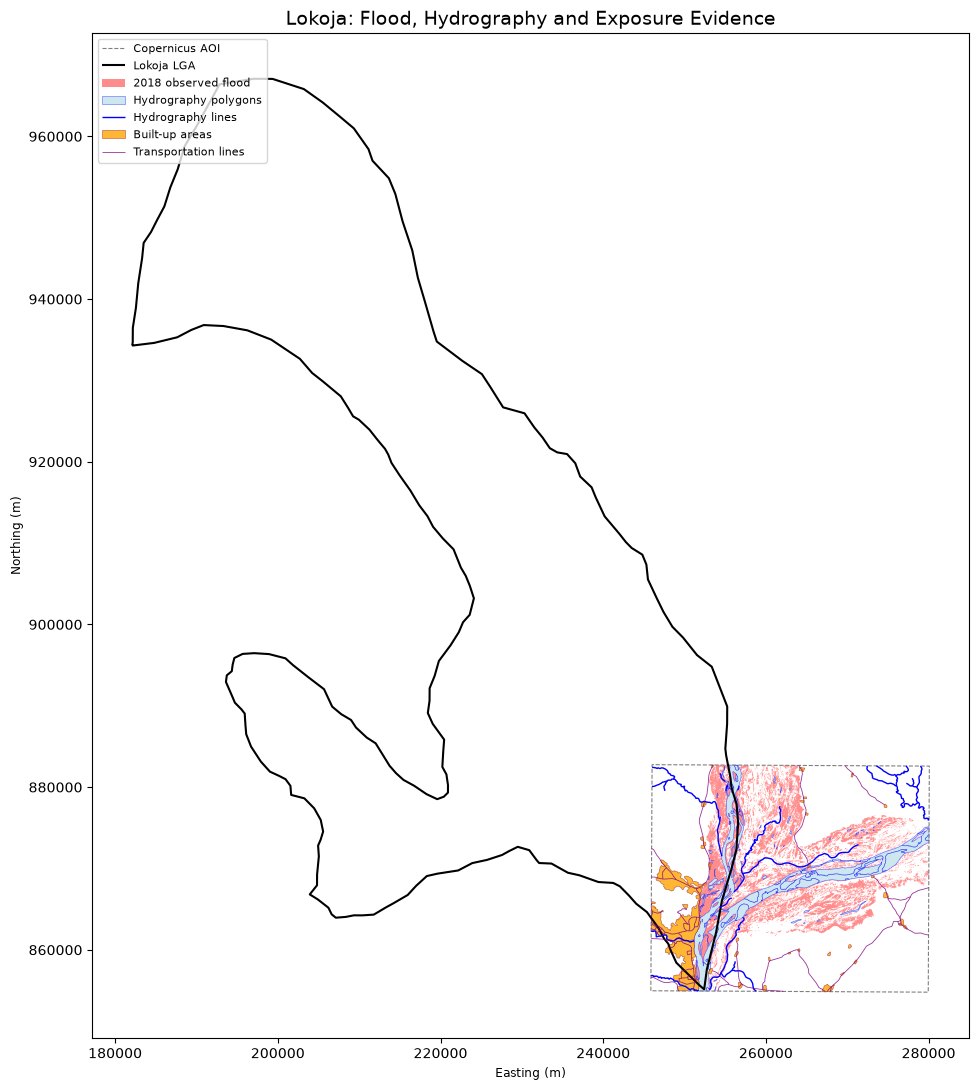


Map saved: /workspaces/nigeria-flood-watch/data/figures/lokoja_local_floodplain_evidence_qa.png


In [20]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Locate Copernicus extracted layers
EXTRACT_DIR = (
    PROJECT_ROOT / "data" / "raw" / "EMSR314_02_extracted"
)

def load_copernicus_layer(keyword):
    matches = [
        p for p in EXTRACT_DIR.rglob("*.shp")
        if keyword.lower() in p.stem.lower()
    ]

    if len(matches) != 1:
        raise ValueError(
            f"Expected one layer for {keyword}; found: {matches}"
        )

    return gpd.read_file(matches[0])


# Load relevant layers
hydro_a = load_copernicus_layer("hydrography_a")
hydro_l = load_copernicus_layer("hydrography_l")
built_up = load_copernicus_layer("built_up_a")
roads = load_copernicus_layer("transportation_l")
transport_points = load_copernicus_layer("transportation_p")
physiography = load_copernicus_layer("physiography_l")
aoi = load_copernicus_layer("area_of_interest_a")


# ------------------------------------------------------------
# A. INSPECT HYDROGRAPHY ATTRIBUTES
# ------------------------------------------------------------

print("HYDROGRAPHY POLYGONS")
print(hydro_a["name"].value_counts(dropna=False))

print("\nHYDROGRAPHY LINES")
print(hydro_l["name"].value_counts(dropna=False))

print("\nHYDROGRAPHY LINE OBJECT TYPES")
print(hydro_l["obj_type"].value_counts(dropna=False))

print("\nHYDROGRAPHY POLYGON OBJECT TYPES")
print(hydro_a["obj_type"].value_counts(dropna=False))


# ------------------------------------------------------------
# B. INSPECT BUILT-UP AREAS AND TRANSPORTATION
# ------------------------------------------------------------

print("\nBUILT-UP AREA NAMES")
print(built_up["name"].value_counts(dropna=False).head(30))

print("\nBUILT-UP OBJECT TYPES")
print(built_up["obj_type"].value_counts(dropna=False))

print("\nROAD OBJECT TYPES")
print(roads["obj_type"].value_counts(dropna=False))

print("\nTRANSPORT POINT TYPES")
print(transport_points["obj_type"].value_counts(dropna=False))

print("\nPHYSIOGRAPHY ELEVATION SUMMARY")
print(physiography["elev"].describe())


# ------------------------------------------------------------
# C. PROJECT ALL LAYERS TO EPSG:32632
# ------------------------------------------------------------

layers = {
    "lga": lokoja_lga,
    "flood": flood_gdf,
    "hydro_a": hydro_a,
    "hydro_l": hydro_l,
    "built_up": built_up,
    "roads": roads,
    "transport_points": transport_points,
    "physiography": physiography,
    "aoi": aoi
}

layers_utm = {
    name: layer.to_crs("EPSG:32632")
    for name, layer in layers.items()
}


# ------------------------------------------------------------
# D. INTERSECTION COUNTS WITH LOKOJA LGA
# ------------------------------------------------------------

lga_geom = layers_utm["lga"].geometry.union_all()

print("\nFEATURES INTERSECTING LOKOJA LGA")
print("--------------------------------")

for name in [
    "hydro_a",
    "hydro_l",
    "built_up",
    "roads",
    "transport_points",
    "physiography"
]:
    layer = layers_utm[name]

    intersecting = layer.geometry.intersects(lga_geom)

    print(
        f"{name}: {int(intersecting.sum())} "
        f"of {len(layer)} features"
    )


# ------------------------------------------------------------
# E. CREATE CONTEXT MAP
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 11))

layers_utm["aoi"].boundary.plot(
    ax=ax,
    color="grey",
    linestyle="--",
    linewidth=0.8,
    label="Copernicus AOI"
)

layers_utm["lga"].boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.5,
    label="Lokoja LGA"
)

layers_utm["flood"].plot(
    ax=ax,
    color="red",
    alpha=0.45,
    edgecolor="none",
    label="2018 observed flood"
)

layers_utm["hydro_a"].plot(
    ax=ax,
    color="lightblue",
    alpha=0.6,
    edgecolor="blue",
    linewidth=0.4,
    label="Hydrography polygons"
)

layers_utm["hydro_l"].plot(
    ax=ax,
    color="blue",
    linewidth=1.0,
    label="Hydrography lines"
)

layers_utm["built_up"].plot(
    ax=ax,
    color="orange",
    alpha=0.8,
    edgecolor="brown",
    linewidth=0.4,
    label="Built-up areas"
)

layers_utm["roads"].plot(
    ax=ax,
    color="purple",
    linewidth=0.6,
    alpha=0.8,
    label="Transportation lines"
)

ax.set_title(
    "Lokoja: Flood, Hydrography and Exposure Evidence",
    fontsize=14
)

ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.legend(loc="upper left", fontsize=8)
ax.set_aspect("equal")

plt.tight_layout()

map_path = (
    PROJECT_ROOT /
    "data" /
    "figures" /
    "lokoja_local_floodplain_evidence_qa.png"
)

plt.savefig(map_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nMap saved:", map_path)


In [21]:

# ============================================================
# TASK 3.4.4 — RIVER IDENTITY AND LOCAL DOMAIN DIAGNOSTIC
# ============================================================

import geopandas as gpd
import pandas as pd
from shapely.geometry import box

# Work in projected coordinates
hydro_a_utm = hydro_a.to_crs("EPSG:32632")
hydro_l_utm = hydro_l.to_crs("EPSG:32632")
built_utm = built_up.to_crs("EPSG:32632")
flood_utm = flood_gdf.to_crs("EPSG:32632")
lga_utm = lokoja_lga.to_crs("EPSG:32632")
aoi_utm = aoi.to_crs("EPSG:32632")

lga_geom = lga_utm.geometry.union_all()
aoi_geom = aoi_utm.geometry.union_all()

# 1. Named river polygons
named_rivers = hydro_a_utm[
    hydro_a_utm["name"].isin(["Niger", "Benue"])
].copy()

named_rivers["inside_lga"] = (
    named_rivers.geometry.intersects(lga_geom)
)

named_rivers["inside_aoi"] = (
    named_rivers.geometry.intersects(aoi_geom)
)

named_rivers["area_km2"] = (
    named_rivers.geometry.area / 1_000_000
)

print("NAMED RIVER POLYGONS")
display(
    named_rivers[
        ["name", "obj_type", "inside_lga", "inside_aoi", "area_km2"]
    ]
)

# 2. Named river intersections with flood evidence
flood_union = flood_utm.geometry.union_all()

named_rivers["intersects_2018_flood"] = (
    named_rivers.geometry.intersects(flood_union)
)

print("\nRIVER / FLOOD INTERSECTIONS")
display(
    named_rivers[
        ["name", "inside_lga", "inside_aoi", "intersects_2018_flood"]
    ]
)

# 3. Built-up settlements inside Copernicus AOI
built_in_aoi = built_utm[
    built_utm.geometry.intersects(aoi_geom)
].copy()

print("\nBUILT-UP FEATURES INSIDE COPERNICUS AOI")
display(
    built_in_aoi[
        ["name", "obj_type", "notation"]
    ]
)

# 4. AOI geometry and administrative intersection
aoi_area = aoi_utm.geometry.area.sum() / 1_000_000

aoi_lga_intersection = aoi_geom.intersection(
    lga_geom
)

intersection_area = (
    aoi_lga_intersection.area / 1_000_000
)

print("\nSTUDY AREA MEASUREMENTS")
print("Copernicus AOI:", round(aoi_area, 3), "km²")
print("AOI within Lokoja LGA:", round(intersection_area, 3), "km²")

# 5. Historical flood area inside AOI
flood_in_aoi = flood_union.intersection(aoi_geom)

print(
    "2018 flood area inside AOI:",
    round(flood_in_aoi.area / 1_000_000, 3),
    "km²"
)

print(
    "2018 flood area inside LGA:",
    round(flood_union.intersection(lga_geom).area / 1_000_000, 3),
    "km²"
)


NAMED RIVER POLYGONS


,name,obj_type,inside_lga,inside_aoi,area_km2
0,Benue,BH140-River,False,True,0.170796
1,Benue,BH140-River,False,True,0.197988
2,Benue,BH140-River,True,True,24.482840
3,Niger,BH140-River,True,True,25.739252



RIVER / FLOOD INTERSECTIONS


,name,inside_lga,inside_aoi,intersects_2018_flood
0,Benue,False,True,True
1,Benue,False,True,True
2,Benue,True,True,True
3,Niger,True,True,True



BUILT-UP FEATURES INSIDE COPERNICUS AOI


,name,obj_type,notation
0,Unknown,11-Residential Buildings,Built up area
1,Unknown,11-Residential Buildings,Built up area
2,Unknown,11-Residential Buildings,Built up area
3,Unknown,11-Residential Buildings,Built up area
4,Unknown,11-Residential Buildings,Built up area
5,Atakpa,11-Residential Buildings,Built up area
6,Unknown,11-Residential Buildings,Built up area
7,Unknown,11-Residential Buildings,Built up area
8,Unknown,11-Residential Buildings,Built up area
9,Gbaroada,11-Residential Buildings,Built up area



STUDY AREA MEASUREMENTS
Copernicus AOI: 947.541 km²
AOI within Lokoja LGA: 223.853 km²
2018 flood area inside AOI: 154.759 km²
2018 flood area inside LGA: 36.009 km²


In [22]:

# ============================================================
# NIGERIAFLOODWATCH — TASK 3 FINAL STUDY-AREA EXPORT
# ============================================================

from pathlib import Path
import geopandas as gpd
import pandas as pd

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Work with the AOI in a projected CRS
local_aoi = aoi.to_crs("EPSG:32632").copy()
lga = lokoja_lga.to_crs("EPSG:32632").copy()

# Add descriptive metadata
local_aoi["study_area"] = "Lokoja local analysis extent"
local_aoi["boundary_type"] = "Emergency mapping area of interest"
local_aoi["source"] = "Copernicus EMSR314_02"
local_aoi["status"] = "Provisional pilot analysis boundary"
local_aoi["area_km2"] = (
    local_aoi.geometry.area / 1_000_000
)

# Export in WGS84 for interoperability
local_aoi_export = local_aoi.to_crs("EPSG:4326")

local_aoi_path = (
    PROCESSED_DIR / "lokoja_local_analysis_extent.geojson"
)

local_aoi_export.to_file(
    local_aoi_path,
    driver="GeoJSON"
)

# Create a study-area summary
study_area_summary = pd.DataFrame([
    {
        "study_area": "Administrative",
        "dataset": "lokoja_lga_boundary.geojson",
        "area_km2": lga.geometry.area.sum() / 1_000_000,
        "status": "Finalised"
    },
    {
        "study_area": "Local analysis extent",
        "dataset": "lokoja_local_analysis_extent.geojson",
        "area_km2": local_aoi.geometry.area.sum() / 1_000_000,
        "status": "Provisional"
    },
    {
        "study_area": "Hydrological",
        "dataset": "hydrobasins_combined_upstream_network_lokoja.geojson",
        "area_km2": None,
        "status": "297-feature candidate network verified"
    }
])

summary_path = (
    PROCESSED_DIR / "lokoja_study_area_summary.csv"
)

study_area_summary.to_csv(summary_path, index=False)

print("STUDY AREA EXPORTS COMPLETED")
print("Local analysis extent:", local_aoi_path)
print("Summary:", summary_path)

display(study_area_summary)


STUDY AREA EXPORTS COMPLETED
Local analysis extent: /workspaces/nigeria-flood-watch/data/processed/lokoja_local_analysis_extent.geojson
Summary: /workspaces/nigeria-flood-watch/data/processed/lokoja_study_area_summary.csv


,study_area,dataset,area_km2,status
0,Administrative,lokoja_lga_boundary.geojson,3181.167850,Finalised
1,Local analysis extent,lokoja_local_analysis_extent.geojson,947.540566,Provisional
2,Hydrological,hydrobasins_combined_upstream_network_lokoja.g...,NaN,297-feature candidate network verified
